# Portion 2 — Measurement layer: triangle detection & scientific targets (CPU)
**Input:** the outputs of Portion 1 (`portion1_outputs/`). **Output:** `portion2_outputs/`, including the per-frame target table used by Portions 3–5.

Classical, threshold-documented image analysis (no deep learning is needed here). Each quantity is in **physical units**.

| Quantity | Definition | Valid regime |
|---|---|---|
| `coverage` | footprint coverage = 1 − area of bare-mica patches (low **and** smooth) wider than 2·`R_OPEN_NM`; height threshold adapts to the frame's contrast | all frames with measurable contrast |
| `count_est`, `density_um2` | one triangle = one enclosed central cavity (+ border-cut partial triangles); robust to touching triangles | coverage ≤ 0.6 |
| `clark_evans_R` | mean nearest-neighbour distance / random expectation (R<1 = clustering) | coverage ≤ 0.6 |
| `fft_period_nm`, `fft_peak_ratio`, `fft_psi6` | lattice period, peak sharpness and 6-fold angular order of the FFT ring (threshold-free) | all; meaningful when dense |
| `hole_nn_nm`, `frac_6fold`, `defect_density_um2`, `psi6_local`, `psi6_global` | lattice holes (local height minima) → Delaunay coordination & bond-orientational order | coverage ≥ 0.9 |
| `t50_s`, `t90_s`, `k_per_s`, `theta_inf` | kinetics per concentration (pseudo-first-order fit) | per movie |

Reliability without labels: **trace vs retrace repeatability** and **threshold sensitivity**.
Reliability with labels: a stratified **manual-check set** (150 frames) is exported; fill the CSV and re-run the last section.

**Gate (from the plan):** coverage curves must reproduce the published trends — dense monolayer ≈200 s at 6 nM, slower (≈600 s) at 4 nM,
no further acceleration up to 12 nM. If the gate fails, fix the measurement before any deep learning.

In [1]:
# ---- 0. Mount Google Drive -------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - using local paths.')

Mounted at /content/drive


In [2]:
# ---- 1. Imports ----------------------------------------------------------------
import os, json, time, warnings, platform
from datetime import datetime
import numpy as np
import pandas as pd
import scipy
from scipy import ndimage as ndi
from scipy.optimize import curve_fit
from scipy.spatial import Delaunay, cKDTree
from scipy.stats import spearmanr, pearsonr
import skimage
from skimage import morphology as morph, measure, feature, filters
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
try:
    from joblib import Parallel, delayed
    HAVE_JOBLIB = True
except ImportError:
    HAVE_JOBLIB = False
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
print('numpy', np.__version__, '| pandas', pd.__version__, '| scipy', scipy.__version__, '| skimage', skimage.__version__)

numpy 2.1.3 | pandas 2.2.3 | scipy 1.16.3 | skimage 0.25.2


In [3]:
# ---- 2. Configuration ---------------------------------------------------------------
DATA_DIR = '/content/drive/MyDrive/Koushik-experiment/'
DATA_DIR = os.environ.get('HSAFM_DATA_DIR', DATA_DIR)          # (local-testing override; ignore in Colab)
P1_DIR  = os.path.join(DATA_DIR, 'portion1_outputs')
OUT_DIR = os.path.join(DATA_DIR, 'portion2_outputs')
FIG = os.path.join(OUT_DIR, 'figures'); MAN = os.path.join(OUT_DIR, 'manual_check')
for d in [OUT_DIR, FIG, os.path.join(MAN, 'png')]:
    os.makedirs(d, exist_ok=True)

# Measurement parameters (physical units; fixed for every frame)
T_ABS_NM        = 0.8    # upper limit of the mica/origami threshold (isolated origami ~2 nm above mica)
T_REL           = 0.40   # threshold = T_REL x 99th-percentile height of the frame ...
T_MIN_NM        = 0.30   # ... clipped to [T_MIN_NM, T_ABS_NM]
R_OPEN_NM       = 20.0   # bare-mica patches narrower than 2*R are counted as covered (lattice interstices, triangle cavity)
MIN_OBJ_NM2     = 800.0  # covered specks smaller than this are noise
CAVITY_MIN_NM2  = 150.0  # enclosed central cavity of one triangle (counting)
CAVITY_MAX_NM2  = 6000.0
PARTIAL_MIN_NM2 = 1500.0 # border-cut triangle without visible cavity still counts as one
MICA_WIN_NM     = 15.0   # window for local roughness
MICA_MAX_STD_NM = 0.25   # bare mica local RMS is ~0.05-0.15 nm; lattice texture 0.2-0.6 nm
MICA_NOISE_FACTOR = 3.0  # ...or 3x the frame's own noise floor, whichever is larger
LOW_CONTRAST_NM = 0.9    # p99-p1 range below this AND a lattice FFT peak = contrast too compressed -> coverage unmeasurable
SPARSE_MAX_COV  = 0.60   # counting / clustering valid up to this coverage
DENSE_MIN_COV   = 0.90   # lattice metrics valid from this coverage
PERIOD_RANGE_NM = (30.0, 200.0)   # search range for the FFT lattice peak
HOLE_SMOOTH_NM  = 6.0    # Gaussian smoothing before hole (local-minimum) detection
LATTICE_PEAK_MIN = 5.0   # FFT peak ratio above which a lattice is "detected"
SENS_T          = (0.75, 1.25)    # threshold-sensitivity variants (x adaptive threshold)
SENS_R          = (15.0, 25.0)
RETRACE_EVERY   = 5      # repeatability check on every n-th frame
N_MANUAL        = 150    # manual-check frames (stratified)
N_JOBS          = -1     # CPU workers (joblib); set 1 to disable parallelism
SEED = 0
FORCE = False            # True = recompute per-frame measurements even if cached
MEASURE_VERSION = 'v1.0'  # bump if you edit the measurement functions (invalidates the cache)

assert os.path.exists(os.path.join(P1_DIR, 'frames_all.csv')), 'Run Portion 1 first (portion1_outputs/frames_all.csv missing).'
frames = pd.read_csv(os.path.join(P1_DIR, 'frames_all.csv'))
sessions = pd.read_csv(os.path.join(P1_DIR, 'sessions.csv'))
kept = frames[~frames.exclude.astype(bool)].sort_values(['conc_nM', 't_rel_s']).reset_index(drop=True)
conc_order = lambda c: float(str(c).replace('nM', ''))
CONCS = sorted(kept.conc.unique(), key=conc_order)
print('Concentrations:', CONCS, '| kept frames:', len(kept))
display(kept.groupby('conc').agg(n=('frame_id', 'size'), t_max_s=('t_rel_s', 'max'), nm_per_px=('nm_per_px', 'min')).loc[CONCS])

Concentrations: ['2nM', '4nM', '6nM', '8nM', '10nM'] | kept frames: 4036


,n,t_max_s,nm_per_px
conc,,,
2nM,597,613.881,5.0
4nM,886,1202.092,2.5
6nM,797,1077.355,2.5
8nM,858,1191.087,2.5
10nM,898,1242.055,2.5


In [4]:
# ---- 3. Frame loading ---------------------------------------------------------------------
_STACKS = {}
def get_stack(rel_path, retrace=False):
    fn = os.path.join(P1_DIR, rel_path)
    if retrace:
        fn = fn.replace('_trace.npy', '_retrace.npy')
    if fn not in _STACKS:
        _STACKS[fn] = np.load(fn, mmap_mode='r')
    return _STACKS[fn]

def load_frame(row, retrace=False):
    return np.asarray(get_stack(row['stack_file'], retrace)[int(row['stack_idx'])], dtype=np.float32)

def has_retrace(row):
    return os.path.exists(os.path.join(P1_DIR, row['stack_file']).replace('_trace.npy', '_retrace.npy'))

In [5]:
# ---- 4. Measurement functions ---------------------------------------------------------------
def frame_threshold(h, factor=1.0):
    """mica/origami height threshold scaled to the frame's own height range (robust to compressed imaging contrast):
    T = clip(T_REL * p99(h), T_MIN_NM, T_ABS_NM) * factor"""
    return float(np.clip(T_REL * np.percentile(h, 99), T_MIN_NM, T_ABS_NM) * factor)

def footprint(h, nmpx, T=None, R=R_OPEN_NM):
    """covered-area mask: everything that is not a bare-mica patch at least 2R wide."""
    if T is None:
        T = frame_threshold(h)
    r = max(1, int(round(R / nmpx)))
    w = max(3, int(round(MICA_WIN_NM / nmpx)) | 1)
    mu = ndi.uniform_filter(h, w)
    sd = np.sqrt(np.maximum(ndi.uniform_filter(h * h, w) - mu * mu, 0))
    noise = float(np.percentile(sd, 5))                     # frame's own noise floor (differs trace vs retrace)
    smooth = sd < max(MICA_MAX_STD_NM, MICA_NOISE_FACTOR * noise)
    low = h < T
    seed = low & smooth                                     # bare mica is LOW and SMOOTH; lattice grooves are textured
    seed = ndi.binary_dilation(seed, iterations=w // 2 + 1) & low   # give back low pixels next to edges
    mica = ndi.binary_opening(seed, structure=morph.disk(r).astype(bool))
    cov = ~mica
    lab, n = ndi.label(cov)
    if n == 0:
        return cov
    sizes = np.bincount(lab.ravel())
    small = sizes < max(1, int(MIN_OBJ_NM2 / nmpx ** 2)); small[0] = False
    return cov & ~small[lab]

def fft_lattice(h, nmpx):
    ny, nx = h.shape
    w = np.outer(np.hanning(ny), np.hanning(nx))
    F = np.abs(np.fft.fftshift(np.fft.fft2((h - h.mean()) * w))) ** 2
    yy, xx = np.mgrid[:ny, :nx]
    ky, kx = yy - ny // 2, xx - nx // 2
    F[:, nx // 2 - 1:nx // 2 + 2] = 0      # remove kx≈0 column (scan-line / streak power)
    r = np.hypot(ky, kx)
    ri = np.rint(r).astype(int)
    prof = np.bincount(ri.ravel(), F.ravel()) / np.maximum(np.bincount(ri.ravel()), 1)
    L = nx * nmpx
    kmin = max(2, int(np.floor(L / PERIOD_RANGE_NM[1]))); kmax = min(len(prof) - 2, int(np.ceil(L / PERIOD_RANGE_NM[0])))
    ks = np.arange(kmin, kmax + 1)
    if len(ks) < 3:
        return np.nan, np.nan, np.nan
    kp = int(ks[np.argmax(prof[ks] * ks ** 2)])              # k^2 compensates the 1/f background
    neigh = [k for k in range(int(kp / 1.6), int(kp * 1.6) + 1) if abs(k - kp) > 1 and 1 <= k < len(prof)]
    base = np.median(prof[neigh]) if neigh else np.nan
    ratio = float(prof[kp] / base) if base and base > 0 else np.nan
    ring = (np.abs(r - kp) <= 1.0) & (F > 0)
    th = np.arctan2(ky[ring], kx[ring]); p = F[ring]
    psi6 = float(np.abs(np.sum(p * np.exp(6j * th))) / np.sum(p)) if p.sum() > 0 else np.nan
    return float(L / kp), ratio, psi6

def lattice_holes(h, nmpx, period_nm):
    """Holes of the closed lattice = local height minima; Delaunay coordination and bond-orientational order."""
    out = dict(n_holes=0, hole_nn_nm=np.nan, frac_6fold=np.nan, defect_density_um2=np.nan,
               psi6_local=np.nan, psi6_global=np.nan)
    if not np.isfinite(period_nm):
        return out, np.empty((0, 2))
    sm = filters.gaussian(h, sigma=HOLE_SMOOTH_NM / nmpx)
    md = max(2, int(0.4 * period_nm / nmpx))
    pk = feature.peak_local_max(-sm, min_distance=md, threshold_abs=-np.percentile(sm, 35), exclude_border=False)
    out['n_holes'] = len(pk)
    if len(pk) < 12:
        return out, pk
    pts = pk[:, ::-1].astype(float) * nmpx                   # (x, y) in nm
    d, _ = cKDTree(pts).query(pts, k=2)
    out['hole_nn_nm'] = float(np.median(d[:, 1]))
    tri = Delaunay(pts)
    indptr, nbr = tri.vertex_neighbor_vertices
    ny, nx = h.shape; margin = 1.0 * period_nm
    inner = [(i) for i in range(len(pts)) if margin < pts[i, 0] < nx * nmpx - margin and margin < pts[i, 1] < ny * nmpx - margin]
    if len(inner) < 5:
        return out, pk
    z, psi = [], []
    for i in inner:
        nb = nbr[indptr[i]:indptr[i + 1]]
        v = pts[nb] - pts[i]
        z.append(len(nb)); psi.append(np.mean(np.exp(6j * np.arctan2(v[:, 1], v[:, 0]))))
    z = np.array(z); psi = np.array(psi)
    area_um2 = max((nx * nmpx - 2 * margin) * (ny * nmpx - 2 * margin), 1) / 1e6
    out.update(frac_6fold=float(np.mean(z == 6)), defect_density_um2=float(np.sum(z != 6) / area_um2),
               psi6_local=float(np.mean(np.abs(psi))), psi6_global=float(np.abs(np.mean(psi))))
    return out, pk

def measure_frame(h, nmpx, full=True):
    cov = footprint(h, nmpx)
    Tf = frame_threshold(h)
    m = dict(coverage=float(cov.mean()), origami_frac=float((h > Tf).mean()),
             origami_height_nm=float(np.median(h[h > Tf])) if (h > Tf).any() else np.nan,
             rq_nm=float(h.std()), h_range_nm=float(np.percentile(h, 99) - np.percentile(h, 1)))
    if not full:
        return m, None
    m['threshold_nm'] = frame_threshold(h)
    for fct in SENS_T:
        m[f'coverage_Tx{fct}'] = float(footprint(h, nmpx, T=frame_threshold(h, fct)).mean())
    for R in SENS_R:
        m[f'coverage_R{int(R)}'] = float(footprint(h, nmpx, R=R).mean())
    # triangle counting via the enclosed central cavity of each origami triangle (robust to touching triangles)
    ori = ndi.binary_opening(h > Tf, iterations=1)
    lab_o, _ = ndi.label(ori, structure=np.ones((3, 3)))
    holes = ndi.binary_fill_holes(ori) & ~ori
    hl, nh = ndi.label(holes)
    hsz = np.bincount(hl.ravel())[1:] * nmpx ** 2
    good = np.where((hsz >= CAVITY_MIN_NM2) & (hsz <= CAVITY_MAX_NM2))[0] + 1
    cents = np.array(ndi.center_of_mass(holes, hl, good)).reshape(-1, 2)[:, ::-1] * nmpx if len(good) else np.empty((0, 2))
    ny, nx = h.shape
    goodset = np.zeros(nh + 1, bool); goodset[good] = True
    partial = 0
    for p in measure.regionprops(lab_o):
        r0, c0, r1, c1 = p.bbox
        if (r0 == 0 or c0 == 0 or r1 == ny or c1 == nx) and p.area * nmpx ** 2 >= PARTIAL_MIN_NM2:
            if not goodset[hl[p.slice][p.image]].any():
                partial += 1
    m['n_cavities'] = int(len(good)); m['n_border_partial'] = int(partial)
    m['n_objects'] = int(lab_o.max())
    m['_cents'] = cents
    m['fft_period_nm'], m['fft_peak_ratio'], m['fft_psi6'] = fft_lattice(h, nmpx)
    holes, pk = lattice_holes(h, nmpx, m['fft_period_nm']) if m['coverage'] >= DENSE_MIN_COV else (
        dict(n_holes=np.nan, hole_nn_nm=np.nan, frac_6fold=np.nan, defect_density_um2=np.nan,
             psi6_local=np.nan, psi6_global=np.nan), np.empty((0, 2)))
    m.update(holes)
    return m, pk

In [6]:
# ---- 5. Run measurements on all kept frames (cached) ------------------------------------------
PARAM_KEY = json.dumps({k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, tuple))
                       and k not in ('DATA_DIR', 'P1_DIR', 'OUT_DIR', 'FIG', 'MAN', 'N_JOBS', 'FORCE', 'N_MANUAL')}, sort_keys=True, default=str)
cache = os.path.join(OUT_DIR, '_measure_cache.pkl'); cache_key = cache + '.key'

def _job(stack_file, stack_idx, nmpx):
    h = np.asarray(np.load(os.path.join(P1_DIR, stack_file), mmap_mode='r')[int(stack_idx)], dtype=np.float32)
    m, _ = measure_frame(h, nmpx)
    return m

if os.path.exists(cache) and os.path.exists(cache_key) and not FORCE:
    raw_meas = pd.read_pickle(cache)
    if set(raw_meas.frame_id) != set(kept.frame_id) or open(cache_key).read() != PARAM_KEY:
        print('cache does not match current frames/parameters -> recomputing'); raw_meas = None
    else:
        print('using cached measurements (same frames and parameters)')
else:
    raw_meas = None
if raw_meas is None:
    t0 = time.time()
    args = list(zip(kept.stack_file, kept.stack_idx, kept.nm_per_px))
    if HAVE_JOBLIB and N_JOBS != 1:
        res = Parallel(n_jobs=N_JOBS, batch_size=16, verbose=0)(delayed(_job)(*a) for a in args)
    else:
        res = [_job(*a) for a in args]
    raw_meas = pd.DataFrame(res); raw_meas.insert(0, 'frame_id', kept.frame_id.values)
    raw_meas.to_pickle(cache); open(cache_key, 'w').write(PARAM_KEY)
    print(f'measured {len(raw_meas)} frames in {time.time()-t0:.0f}s')

meas = kept[['frame_id', 'conc', 'conc_nM', 'session', 't_rel_s', 't_session_s', 'nx', 'nm_per_px',
             'stack_file', 'stack_idx', 'member']].merge(raw_meas, on='frame_id')
print(meas[['coverage', 'n_objects', 'fft_period_nm', 'fft_peak_ratio']].describe().round(3))

measured 4036 frames in 975s
       coverage  n_objects  fft_period_nm  fft_peak_ratio
count  4036.000   4036.000       4036.000        4036.000
mean      0.789     12.295         76.488           4.206
std       0.334     15.918         44.555           2.419
min       0.076      1.000         29.412           0.354
25%       0.573      5.000         58.824           2.436
50%       0.997      9.000         66.667           3.461
75%       1.000     14.000         66.667           5.417
max       1.000    493.000        250.000          15.918


In [7]:
# ---- 6. Counting and clustering (sparse regime) ---------------------------------------------------------
def clark_evans(cents, n, L_nm):
    if n < 5 or len(cents) < 5:
        return np.nan
    d, _ = cKDTree(cents).query(cents, k=2)
    dens = len(cents) / (L_nm ** 2)
    return float(np.mean(d[:, 1]) / (0.5 / np.sqrt(dens)))

meas['count_est'] = (meas.n_cavities + meas.n_border_partial).astype(float)
L = meas.nx * meas.nm_per_px
meas['density_um2'] = meas.count_est / (L / 1000) ** 2
meas['clark_evans_R'] = [clark_evans(c, n, l) for c, n, l in zip(meas._cents, meas.count_est, L)]
meas['count_valid'] = meas.coverage <= SPARSE_MAX_COV
meas['lattice_valid'] = meas.coverage >= DENSE_MIN_COV
meas.loc[~meas.count_valid, ['count_est', 'density_um2', 'clark_evans_R']] = np.nan
meas['lattice_detected'] = (meas.fft_peak_ratio >= LATTICE_PEAK_MIN) & meas.lattice_valid
meas['regime'] = np.select([meas.coverage <= SPARSE_MAX_COV, meas.coverage < DENSE_MIN_COV], ['sparse', 'transition'], 'dense')
# compressed-contrast frames: a lattice is visible (FFT peak) but the whole height range is < LOW_CONTRAST_NM,
# so mica cannot be separated from origami by height -> coverage/counts are NOT measurable (set NaN, never guessed)
meas['contrast_ok'] = ~((meas.h_range_nm < LOW_CONTRAST_NM) & (meas.fft_peak_ratio >= 3.0))
bad = ~meas.contrast_ok
cov_like = ['coverage', 'origami_frac', 'count_est', 'density_um2', 'clark_evans_R'] + \
           [c for c in meas.columns if c.startswith('coverage_T') or c.startswith('coverage_R')]
meas.loc[bad, cov_like] = np.nan
meas.loc[bad, ['count_valid', 'lattice_valid', 'lattice_detected']] = False
meas.loc[bad, 'regime'] = 'low_contrast'
print(f'low-contrast (unmeasurable) frames: {int(bad.sum())} of {len(meas)}')
print(meas.groupby(['conc', 'regime']).size().unstack(fill_value=0).loc[CONCS])

low-contrast (unmeasurable) frames: 0 of 4036
regime  dense  sparse  transition
conc                             
2nM         0     597           0
4nM       511     282          93
6nM       712      22          63
8nM       728      48          82
10nM      793      86          19


In [8]:
# ---- 7. Kinetics per concentration ---------------------------------------------------------------------
def pfo(t, th_inf, th0, k):
    return th_inf - (th_inf - th0) * np.exp(-k * t)

def first_sustained(t, y, thr, n_after=3, tol=0.02):
    for i in range(len(y)):
        if y[i] >= thr and np.all(y[i:i + n_after + 1] >= thr - tol):
            return float(t[i])
    return np.nan

kin = []
for c in CONCS:
    g = meas[(meas.conc == c) & meas.contrast_ok].sort_values('t_rel_s')
    t = g.t_rel_s.values; y = g.coverage.rolling(5, center=True, min_periods=1).median().values
    rec = dict(conc=c, conc_nM=conc_order(c), n_frames=len(g), t_end_s=float(t.max()),
               coverage_t0=float(y[0]), coverage_end=float(y[-1]),
               left_censored=bool(y[0] >= 0.5),
               t50_s=first_sustained(t, y, 0.5), t90_s=first_sustained(t, y, 0.9), t95_s=first_sustained(t, y, 0.95))
    ld = g[g.lattice_detected]
    rec['t_lattice_s'] = float(ld.t_rel_s.min()) if len(ld) else np.nan
    try:
        p, cv = curve_fit(pfo, t, g.coverage.values, p0=[float(np.clip(y.max(), 0.01, 0.99)), float(np.clip(y[0], 0.0, 0.99)), 0.01],
                          bounds=([0, 0, 1e-6], [1.0, 1.0, 2.0]), maxfev=20000)
        pred = pfo(t, *p); ss = np.sum((g.coverage.values - pred) ** 2); st = np.sum((g.coverage.values - g.coverage.mean()) ** 2)
        se = np.sqrt(np.diag(cv))
        rec.update(theta_inf=p[0], theta0=p[1], k_per_s=p[2], k_se=se[2], t_half_s=np.log(2) / p[2], fit_R2=1 - ss / st if st > 0 else np.nan)
    except Exception as e:
        rec.update(theta_inf=np.nan, theta0=np.nan, k_per_s=np.nan, k_se=np.nan, t_half_s=np.nan, fit_R2=np.nan)
        print(f'[{c}] kinetic fit failed: {e}')
    rho = spearmanr(t, g.coverage.values).statistic if len(g) > 3 else np.nan
    rec['spearman_t_cov'] = float(rho)
    kin.append(rec)
kin = pd.DataFrame(kin)
display(kin.round(4))
print('Times are seconds since the FIRST RECORDED frame (not since injection). left_censored=True means coverage was '
      'already >=50 % in the first frame, i.e. the early adsorption happened before recording started.')

,conc,conc_nM,n_frames,t_end_s,coverage_t0,coverage_end,left_censored,t50_s,t90_s,t95_s,t_lattice_s,theta_inf,theta0,k_per_s,k_se,t_half_s,fit_R2,spearman_t_cov
0,2nM,2.0,597,613.881,0.1198,0.0945,False,NaN,NaN,NaN,NaN,0.0,0.1610,0.0009,0.0004,741.1103,0.6252,-0.7815
1,4nM,4.0,886,1202.092,0.3171,0.9983,False,267.800,386.250,408.910,422.300,1.0,0.1099,0.0040,0.0001,172.3295,0.8720,0.9598
2,6nM,6.0,797,1077.355,0.3522,0.9983,False,13.492,86.520,94.760,256.470,1.0,0.3062,0.0232,0.0002,29.8741,0.9844,0.5492
3,8nM,8.0,858,1191.087,0.8988,1.0000,True,0.000,131.840,138.021,270.891,1.0,0.3646,0.0117,0.0003,59.4337,0.8747,0.6243
4,10nM,10.0,898,1242.055,0.4823,1.0000,False,75.191,103.001,109.181,262.651,1.0,0.0092,0.0146,0.0004,47.4964,0.8825,0.4623


Times are seconds since the FIRST RECORDED frame (not since injection). left_censored=True means coverage was already >=50 % in the first frame, i.e. the early adsorption happened before recording started.


In [9]:
# ---- 8. Repeatability (trace vs retrace) and threshold sensitivity -------------------------------------------
rep = []
sub = meas[meas.contrast_ok].iloc[::RETRACE_EVERY]
for _, r in sub.iterrows():
    if not has_retrace(r):
        continue
    hr = load_frame(r, retrace=True)
    m2, _ = measure_frame(hr, r.nm_per_px)
    rep.append(dict(frame_id=r.frame_id, conc=r.conc, regime=r.regime,
                    cov_trace=r.coverage, cov_retrace=m2['coverage'],
                    period_trace=r.fft_period_nm, period_retrace=m2['fft_period_nm'],
                    count_trace=r.count_est, count_retrace=float(m2['n_cavities'] + m2['n_border_partial']) if r.count_valid else np.nan))
rep = pd.DataFrame(rep)
rep_summary = {}
if len(rep):
    rep_summary = dict(n=len(rep),
                       coverage_MAE=float(np.mean(np.abs(rep.cov_trace - rep.cov_retrace))),
                       coverage_r=float(pearsonr(rep.cov_trace, rep.cov_retrace)[0]) if rep.cov_trace.std() > 0 else np.nan,
                       coverage_bias_retrace_minus_trace=float(np.mean(rep.cov_retrace - rep.cov_trace)),
                       count_MAE=float(np.nanmean(np.abs(rep.count_trace - rep.count_retrace))),
                       period_MAE_nm_dense=float(np.nanmean(np.abs(rep.period_trace - rep.period_retrace)[rep.regime == 'dense'])) if (rep.regime == 'dense').any() else np.nan)
print('Trace-vs-retrace repeatability:', {k: round(v, 4) if isinstance(v, float) else v for k, v in rep_summary.items()})
sens_cols = [c for c in meas.columns if c.startswith('coverage_T') or c.startswith('coverage_R')]
sens = pd.DataFrame({c: [float(np.nanmean(np.abs(meas[c] - meas.coverage))), float(np.nanmax(np.abs(meas[c] - meas.coverage)))] for c in sens_cols},
                    index=['MAE_vs_default', 'max_abs_diff']).T
print('\nCoverage sensitivity to the threshold choices:'); display(sens.round(4))

Trace-vs-retrace repeatability: {'n': 808, 'coverage_MAE': 0.024, 'coverage_r': 0.993, 'coverage_bias_retrace_minus_trace': 0.024, 'count_MAE': 1.2657, 'period_MAE_nm_dense': 1.2855}

Coverage sensitivity to the threshold choices:


,MAE_vs_default,max_abs_diff
coverage_Tx0.75,0.0119,0.3401
coverage_Tx1.25,0.0099,0.5371
coverage_R15,0.0121,0.1489
coverage_R25,0.0092,0.1357


In [10]:
# ---- 9. Save target table ---------------------------------------------------------------------------------------
target_cols = ['frame_id', 'conc', 'conc_nM', 'session', 't_rel_s', 't_session_s', 'nm_per_px', 'regime',
               'contrast_ok', 'coverage', 'threshold_nm', 'origami_frac', 'origami_height_nm', 'rq_nm', 'h_range_nm', 'n_objects', 'count_est', 'density_um2',
               'clark_evans_R', 'n_cavities', 'n_border_partial', 'count_valid', 'fft_period_nm', 'fft_peak_ratio', 'fft_psi6', 'lattice_valid',
               'lattice_detected', 'n_holes', 'hole_nn_nm', 'frac_6fold', 'defect_density_um2', 'psi6_local',
               'psi6_global'] + sens_cols
meas[target_cols].to_csv(os.path.join(OUT_DIR, 'targets_per_frame.csv'), index=False)
kin.to_csv(os.path.join(OUT_DIR, 'kinetics_per_concentration.csv'), index=False)
rep.to_csv(os.path.join(OUT_DIR, 'repeatability_trace_retrace.csv'), index=False)
sens.to_csv(os.path.join(OUT_DIR, 'coverage_threshold_sensitivity.csv'))
cfg = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, tuple, bool))}
cfg.update(created=datetime.now().isoformat(timespec='seconds'),
           numpy=np.__version__, skimage=skimage.__version__, python=platform.python_version())
json.dump(cfg, open(os.path.join(OUT_DIR, 'measurement_config.json'), 'w'), indent=1, default=str)
print('saved targets_per_frame.csv', meas[target_cols].shape)

saved targets_per_frame.csv (4036, 37)


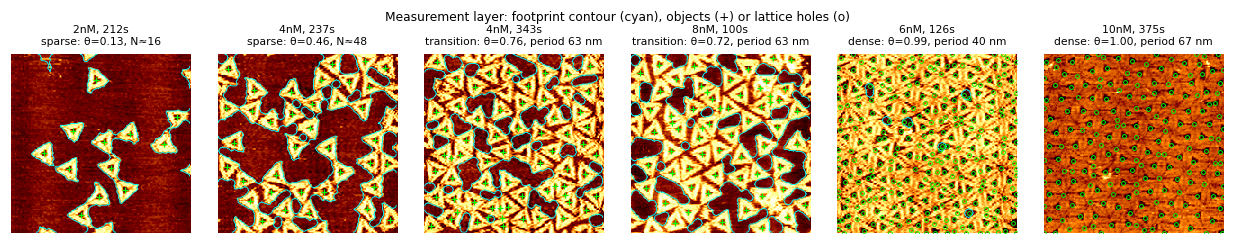

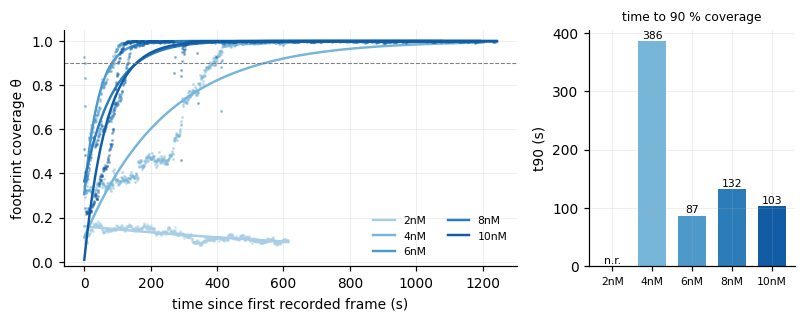

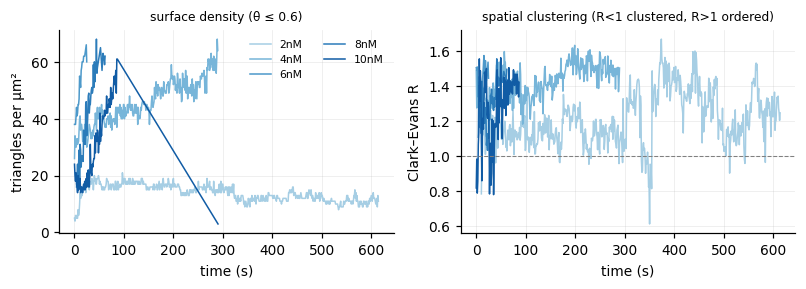

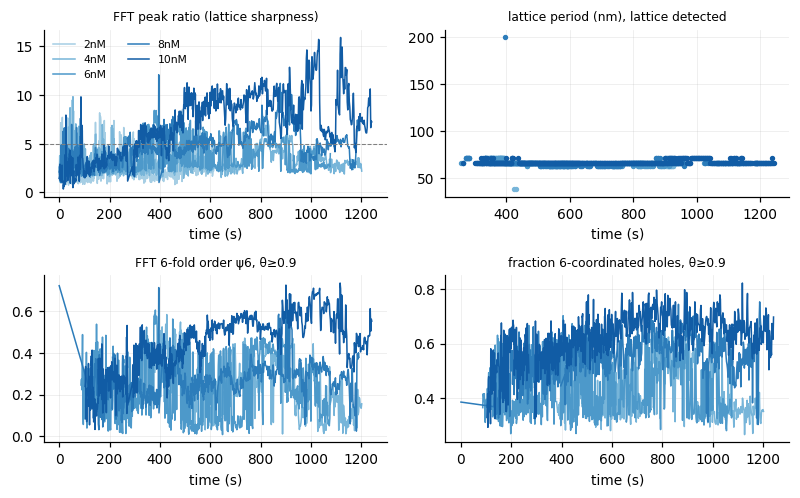

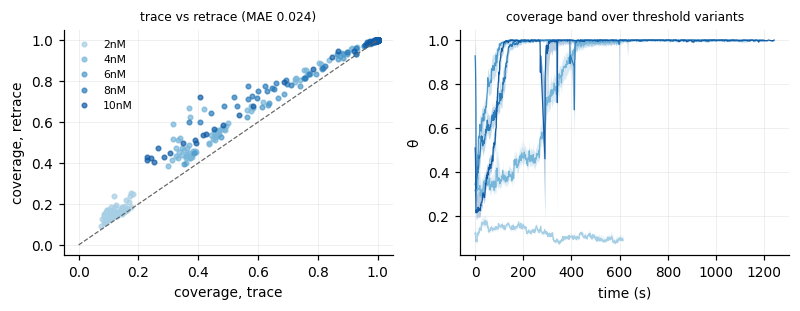

In [11]:
# ---- 10. Figures ----------------------------------------------------------------------------------------------------
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
                     'lines.linewidth': 1.6, 'legend.frameon': False})
_ALL = ['2nM', '4nM', '6nM', '8nM', '10nM', '12nM']
_cm = plt.get_cmap('Blues')
CCOL = {c: _cm(0.35 + 0.6 * i / (len(_ALL) - 1)) for i, c in enumerate(_ALL)}

def overlay(ax, r, title=''):
    h = load_frame(r); nmpx = r.nm_per_px
    cov = footprint(h, nmpx)
    ax.imshow(h, cmap='afmhot', vmin=-0.5, vmax=2.5, interpolation='nearest')
    ax.contour(cov, levels=[0.5], colors='cyan', linewidths=0.6)
    m, pk = measure_frame(h, nmpx)
    if r.regime == 'dense' and len(pk):
        ax.plot(pk[:, 1], pk[:, 0], 'o', ms=2.5, mfc='none', mec='lime', mew=0.6)
    elif len(m['_cents']):
        c = m['_cents'] / nmpx
        ax.plot(c[:, 0], c[:, 1], '+', ms=4, color='lime', mew=0.8)
    ax.set_title(title, fontsize=7); ax.axis('off')

# Fig P2-1: detection overlays for each regime
ex = []
for reg in ['sparse', 'transition', 'dense']:
    g = meas[meas.regime == reg]
    if len(g):
        ex += [g.iloc[int(q * (len(g) - 1))] for q in (0.2, 0.8)]
if ex:
    fig, axes = plt.subplots(1, len(ex), figsize=(1.9 * len(ex), 2.2), squeeze=False)
    for ax, r in zip(axes[0], ex):
        cnt = f'N≈{r.count_est:.0f}' if r.count_valid else f'period {r.fft_period_nm:.0f} nm'
        overlay(ax, r, f'{r.conc}, {r.t_rel_s:.0f}s\n{r.regime}: θ={r.coverage:.2f}, {cnt}')
    fig.suptitle('Measurement layer: footprint contour (cyan), objects (+) or lattice holes (o)', fontsize=8)
    fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP2_1_detection_overlays.png')); plt.show()

# Fig P2-2: coverage kinetics + fitted pseudo-first-order curves; t90 per concentration
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.0), gridspec_kw={'width_ratios': [2.2, 1]})
for c in CONCS:
    g = meas[meas.conc == c].sort_values('t_rel_s'); k = kin[kin.conc == c].iloc[0]
    axes[0].plot(g.t_rel_s, g.coverage, '.', ms=2, color=CCOL.get(c, 'k'), alpha=0.35)
    if np.isfinite(k.k_per_s):
        tt = np.linspace(0, g.t_rel_s.max(), 300)
        axes[0].plot(tt, pfo(tt, k.theta_inf, k.theta0, k.k_per_s), color=CCOL.get(c, 'k'), label=c)
    else:
        axes[0].plot([], [], color=CCOL.get(c, 'k'), label=c)
axes[0].axhline(0.9, color='0.5', ls='--', lw=0.7)
axes[0].set_xlabel('time since first recorded frame (s)'); axes[0].set_ylabel('footprint coverage θ')
axes[0].set_ylim(-0.02, 1.05); axes[0].legend(ncol=2, fontsize=7, loc='lower right')
xs = np.arange(len(CONCS)); t90 = kin.set_index('conc').loc[CONCS, 't90_s']
axes[1].bar(xs, t90.fillna(0), color=[CCOL.get(c, 'k') for c in CONCS], width=0.7)
for x, v in zip(xs, t90):
    axes[1].text(x, (0 if np.isnan(v) else v) + 5, 'n.r.' if np.isnan(v) else f'{v:.0f}', ha='center', fontsize=7)
axes[1].set_xticks(xs); axes[1].set_xticklabels(CONCS, fontsize=7); axes[1].set_ylabel('t90 (s)'); axes[1].set_title('time to 90 % coverage', fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP2_2_coverage_kinetics.png')); plt.show()

# Fig P2-3: sparse-regime counting and clustering
fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.7))
for c in CONCS:
    g = meas[(meas.conc == c) & meas.count_valid].sort_values('t_rel_s')
    axes[0].plot(g.t_rel_s, g.density_um2, color=CCOL.get(c, 'k'), lw=1, label=c)
    axes[1].plot(g.t_rel_s, g.clark_evans_R, color=CCOL.get(c, 'k'), lw=1)
axes[0].set_ylabel('triangles per µm²'); axes[1].set_ylabel('Clark–Evans R'); axes[1].axhline(1, color='0.5', ls='--', lw=0.7)
for ax in axes: ax.set_xlabel('time (s)')
axes[0].legend(fontsize=7, ncol=2); axes[0].set_title(f'surface density (θ ≤ {SPARSE_MAX_COV})', fontsize=8)
axes[1].set_title('spatial clustering (R<1 clustered, R>1 ordered)', fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP2_3_counting_clustering.png')); plt.show()

# Fig P2-4: lattice order metrics
fig, axes = plt.subplots(2, 2, figsize=(7.4, 4.6))
for c in CONCS:
    g = meas[meas.conc == c].sort_values('t_rel_s'); gd = g[g.lattice_valid]; gl = g[g.lattice_detected]
    kw = dict(color=CCOL.get(c, 'k'), lw=1, label=c)
    axes[0, 0].plot(g.t_rel_s, g.fft_peak_ratio, **kw)
    axes[0, 1].plot(gl.t_rel_s, gl.fft_period_nm, 'o', ms=2.5, color=CCOL.get(c, 'k'))
    axes[1, 0].plot(gd.t_rel_s, gd.fft_psi6, **kw)
    axes[1, 1].plot(gd.t_rel_s, gd.frac_6fold, **kw)
for ax, t in zip(axes.ravel(), ['FFT peak ratio (lattice sharpness)', 'lattice period (nm), lattice detected',
                                 'FFT 6-fold order ψ6, θ≥0.9', 'fraction 6-coordinated holes, θ≥0.9']):
    ax.set_title(t, fontsize=8); ax.set_xlabel('time (s)')
axes[0, 0].axhline(LATTICE_PEAK_MIN, color='0.5', ls='--', lw=0.7); axes[0, 0].legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP2_4_lattice_order.png')); plt.show()

# Fig P2-5: reliability without labels
fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.9))
if len(rep):
    for c in CONCS:
        g = rep[rep.conc == c]
        axes[0].plot(g.cov_trace, g.cov_retrace, 'o', ms=3, color=CCOL.get(c, 'k'), label=c, alpha=0.7)
    axes[0].plot([0, 1], [0, 1], color='0.4', lw=0.8, ls='--')
    axes[0].set_title(f'trace vs retrace (MAE {rep_summary["coverage_MAE"]:.3f})', fontsize=8)
axes[0].set_xlabel('coverage, trace'); axes[0].set_ylabel('coverage, retrace'); axes[0].legend(fontsize=7)
for c in CONCS:
    g = meas[meas.conc == c].sort_values('t_rel_s')
    lo_ = g[[x for x in sens_cols]].min(axis=1); hi_ = g[[x for x in sens_cols]].max(axis=1)
    axes[1].fill_between(g.t_rel_s, lo_, hi_, color=CCOL.get(c, 'k'), alpha=0.3, lw=0)
    axes[1].plot(g.t_rel_s, g.coverage, color=CCOL.get(c, 'k'), lw=0.8)
axes[1].set_title('coverage band over threshold variants', fontsize=8); axes[1].set_xlabel('time (s)'); axes[1].set_ylabel('θ')
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP2_5_reliability.png')); plt.show()

In [12]:
# ---- 11. Export the stratified manual-check set ------------------------------------------------------------------------
tmpl = os.path.join(MAN, 'manual_check_template.csv')
filled = os.path.join(MAN, 'manual_check_filled.csv')
stale = (os.path.exists(tmpl) and not os.path.exists(filled)
         and set(pd.read_csv(tmpl).conc.unique()) != set(CONCS))     # new concentration uploaded since export
if stale:
    print('manual-check set does not cover all concentrations yet -> re-exporting (not filled yet, nothing lost)')
    for f_ in os.listdir(os.path.join(MAN, 'png')):
        os.remove(os.path.join(MAN, 'png', f_))
if not os.path.exists(tmpl) or FORCE or stale:
    rng = np.random.default_rng(SEED)
    strata = meas[meas.contrast_ok].groupby(['conc', 'regime', 'nx'])
    per = max(1, int(np.ceil(N_MANUAL / max(1, strata.ngroups))))
    pick = pd.concat([g.iloc[np.sort(rng.choice(len(g), min(per, len(g)), replace=False))] for _, g in strata])
    if len(pick) < N_MANUAL:                                  # top up from the remaining frames
        rest = meas[meas.contrast_ok & ~meas.frame_id.isin(pick.frame_id)]
        pick = pd.concat([pick, rest.sample(n=min(N_MANUAL - len(pick), len(rest)), random_state=SEED)])
    pick = pick.sample(n=min(N_MANUAL, len(pick)), random_state=SEED).sort_values(['conc_nM', 't_rel_s'])
    rows = []
    for i, (_, r) in enumerate(pick.iterrows()):
        cid = f'MC{i:03d}'
        fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
        h = load_frame(r)
        axes[0].imshow(h, cmap='afmhot', vmin=-0.5, vmax=2.5); axes[0].set_title(f'{cid} raw (count here)', fontsize=8); axes[0].axis('off')
        overlay(axes[1], r, f'auto: θ={r.coverage:.2f}  N≈{r.count_est if r.count_valid else float("nan"):.0f}  ({r.regime})')
        fig.tight_layout(); fig.savefig(os.path.join(MAN, 'png', f'{cid}.png'), dpi=120); plt.close(fig)
        rows.append(dict(check_id=cid, frame_id=r.frame_id, conc=r.conc, t_rel_s=round(r.t_rel_s, 2), regime=r.regime,
                         auto_coverage=round(r.coverage, 4), auto_count=r.count_est if r.count_valid else '',
                         manual_count='', coverage_contour_ok='', lattice_visible='', notes=''))
    pd.DataFrame(rows).to_csv(tmpl, index=False)
    print(f'exported {len(rows)} manual-check frames to {MAN}')
else:
    print('manual-check template already exists:', tmpl)
print('''HOW TO USE: open manual_check/png/MCxxx.png. In manual_check_template.csv fill
  manual_count        = number of triangles you count (sparse/transition frames; leave blank for dense),
  coverage_contour_ok = 1 if the cyan contour follows the origami edges, else 0,
  lattice_visible     = 1 if a closed lattice is visible, else 0.
Save it as manual_check_filled.csv in the same folder and re-run the next cell.''')

exported 150 manual-check frames to /content/drive/MyDrive/Koushik-experiment/portion2_outputs/manual_check
HOW TO USE: open manual_check/png/MCxxx.png. In manual_check_template.csv fill
  manual_count        = number of triangles you count (sparse/transition frames; leave blank for dense),
  coverage_contour_ok = 1 if the cyan contour follows the origami edges, else 0,
  lattice_visible     = 1 if a closed lattice is visible, else 0.
Save it as manual_check_filled.csv in the same folder and re-run the next cell.


In [13]:
# ---- 12. Agreement with manual reference (runs only once the filled CSV exists) ---------------------------------
if os.path.exists(filled):
    mc = pd.read_csv(filled)
    mcc = mc.dropna(subset=['manual_count', 'auto_count'])
    res = {'n_frames_checked': len(mc)}
    if len(mcc) >= 3:
        err = mcc.auto_count - mcc.manual_count
        res.update(count_MAE=float(np.mean(np.abs(err))), count_MAPE_pct=float(100 * np.mean(np.abs(err) / mcc.manual_count.clip(lower=1))),
                   count_bias=float(err.mean()), count_LoA_95=(float(err.mean() - 1.96 * err.std()), float(err.mean() + 1.96 * err.std())),
                   count_pearson_r=float(pearsonr(mcc.auto_count, mcc.manual_count)[0]))
        fig, axes = plt.subplots(1, 2, figsize=(7, 3))
        axes[0].scatter(mcc.manual_count, mcc.auto_count, s=10, color=CCOL['6nM'])
        mx = max(mcc.manual_count.max(), mcc.auto_count.max()) + 2
        axes[0].plot([0, mx], [0, mx], '--', color='0.4', lw=0.8); axes[0].set_xlabel('manual count'); axes[0].set_ylabel('automatic count')
        mean_ = (mcc.auto_count + mcc.manual_count) / 2
        axes[1].scatter(mean_, err, s=10, color=CCOL['6nM']); axes[1].axhline(err.mean(), color='0.3', lw=0.8)
        for v in res['count_LoA_95']: axes[1].axhline(v, color='0.5', ls='--', lw=0.8)
        axes[1].set_xlabel('mean of methods'); axes[1].set_ylabel('auto − manual'); axes[1].set_title('Bland–Altman', fontsize=8)
        fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP2_6_manual_agreement.png')); plt.show()
    for col in ['coverage_contour_ok', 'lattice_visible']:
        if col in mc and mc[col].notna().any():
            res[f'{col}_rate'] = float(mc[col].dropna().astype(float).mean())
    if 'lattice_visible' in mc and mc.lattice_visible.notna().any():
        j = mc.dropna(subset=['lattice_visible']).merge(meas[['frame_id', 'lattice_detected']], on='frame_id')
        tp = int(((j.lattice_visible == 1) & j.lattice_detected).sum()); fp = int(((j.lattice_visible == 0) & j.lattice_detected).sum())
        fn = int(((j.lattice_visible == 1) & ~j.lattice_detected).sum())
        res['lattice_F1'] = 2 * tp / max(1, 2 * tp + fp + fn)
    print(json.dumps(res, indent=1))
    json.dump(res, open(os.path.join(OUT_DIR, 'manual_agreement.json'), 'w'), indent=1)
else:
    print('No manual_check_filled.csv yet - skipping manual agreement (this is expected on the first run).')

No manual_check_filled.csv yet - skipping manual agreement (this is expected on the first run).


In [14]:
# ---- 13. Gate: does the measurement reproduce the published trends? ------------------------------------------------
K = kin.set_index('conc')
def kv(c, col):
    return float(K.loc[c, col]) if c in K.index else np.nan
t90_6, t90_4 = kv('6nM', 't90_s'), kv('4nM', 't90_s')
gates = []
gates.append(('6 nM reaches dense coverage (t90) within ~50-400 s (published ≈200 s after injection)',
              'MISSING' if '6nM' not in K.index else ('PASS' if 50 <= t90_6 <= 400 else 'CHECK'), f't90(6nM) = {t90_6:.0f} s'))
if '4nM' not in K.index or '6nM' not in K.index:
    gates.append(('4 nM slower than 6 nM (published ≈600 s)', 'MISSING', 'needs 4 nM and 6 nM'))
else:
    gates.append(('4 nM slower than 6 nM (published ≈600 s)',
                  'PASS' if (t90_4 > t90_6 or (np.isnan(t90_4) and np.isfinite(t90_6))) else 'CHECK',
                  f't90(4nM) = {t90_4:.0f} s (n.r. = not reached in the recording)'))
hi = [c for c in CONCS if conc_order(c) >= 8]
if hi and np.isfinite(t90_6):
    ok_hi = all((kv(c, 't90_s') >= 0.5 * t90_6) or (kv(c, 'left_censored')) for c in hi)
    gates.append(('No strong acceleration above 6 nM (t90 >= 0.5 x t90(6nM))', 'PASS' if ok_hi else 'CHECK',
                  ', '.join(f'{c}: {kv(c, "t90_s"):.0f}s' for c in hi)))
else:
    gates.append(('No strong acceleration above 6 nM', 'MISSING', 'needs 6 nM and >= 8 nM'))
mono = [c for c in CONCS if kv(c, 'spearman_t_cov') > 0.5 or kv(c, 'coverage_t0') > 0.9 or kv(c, 'coverage_end') < 0.3]
gates.append(('Coverage increases over time (Spearman > 0.5, or already saturated / stays sparse)',
              'PASS' if len(mono) == len(CONCS) else 'CHECK', ', '.join(f'{c}:{kv(c, "spearman_t_cov"):.2f}' for c in CONCS)))
gates.append(('Trace-retrace coverage: MAE < 0.05 and r > 0.95',
              'PASS' if (rep_summary.get('coverage_MAE', 1) < 0.05 and rep_summary.get('coverage_r', 0) > 0.95) else 'CHECK',
              f'MAE {rep_summary.get("coverage_MAE", float("nan")):.4f}, r {rep_summary.get("coverage_r", float("nan")):.3f}'))
gates.append(('Trace-retrace triangle count MAE < 1 (sparse frames)', 'PASS' if rep_summary.get('count_MAE', 99) < 1 else 'CHECK',
              f'{rep_summary.get("count_MAE", float("nan")):.2f} triangles'))
gates.append(('Threshold sensitivity: coverage MAE < 0.05 for all variants', 'PASS' if (sens.MAE_vs_default < 0.05).all() else 'CHECK',
              ', '.join(f'{i}:{v:.3f}' for i, v in sens.MAE_vs_default.items())))
gates.append(('Manual-check agreement available', 'PASS' if os.path.exists(filled) else 'TODO',
              'see manual_agreement.json' if os.path.exists(filled) else 'fill manual_check_filled.csv, then re-run'))
G = pd.DataFrame(gates, columns=['gate', 'status', 'detail'])
display(G)
G.to_csv(os.path.join(OUT_DIR, 'gates_portion2.csv'), index=False)
print('\nPASS = reproduced;  CHECK = inspect figures/thresholds;  MISSING = concentration not uploaded;  TODO = manual step.')
print('Outputs:', sorted(os.listdir(OUT_DIR)))

,gate,status,detail
0,6 nM reaches dense coverage (t90) within ~50-4...,PASS,t90(6nM) = 87 s
1,4 nM slower than 6 nM (published ≈600 s),PASS,t90(4nM) = 386 s (n.r. = not reached in the re...
2,No strong acceleration above 6 nM (t90 >= 0.5 ...,PASS,"8nM: 132s, 10nM: 103s"
3,"Coverage increases over time (Spearman > 0.5, ...",CHECK,"2nM:-0.78, 4nM:0.96, 6nM:0.55, 8nM:0.62, 10nM:..."
4,Trace-retrace coverage: MAE < 0.05 and r > 0.95,PASS,"MAE 0.0240, r 0.993"
5,Trace-retrace triangle count MAE < 1 (sparse f...,CHECK,1.27 triangles
6,Threshold sensitivity: coverage MAE < 0.05 for...,PASS,"coverage_Tx0.75:0.012, coverage_Tx1.25:0.010, ..."
7,Manual-check agreement available,TODO,"fill manual_check_filled.csv, then re-run"



PASS = reproduced;  CHECK = inspect figures/thresholds;  MISSING = concentration not uploaded;  TODO = manual step.
Outputs: ['_measure_cache.pkl', '_measure_cache.pkl.key', 'coverage_threshold_sensitivity.csv', 'figures', 'gates_portion2.csv', 'kinetics_per_concentration.csv', 'manual_check', 'measurement_config.json', 'repeatability_trace_retrace.csv', 'targets_per_frame.csv']


## What you have now (`portion2_outputs/`)
| File | Use |
|---|---|
| `targets_per_frame.csv` | **the scientific targets** for Portions 3–5 (coverage, counts, clustering, lattice period/order, defects), one row per kept frame; `regime` and `*_valid` columns say where each quantity is defined |
| `kinetics_per_concentration.csv` | t50 / t90 / t95, lattice onset, pseudo-first-order fit (θ∞, k, t½, R²) per movie |
| `repeatability_trace_retrace.csv`, `coverage_threshold_sensitivity.csv` | label-free reliability of the measurement layer |
| `manual_check/` | 150 stratified PNGs + template → your manual reference set (Methods: "manually verified subset") |
| `figures/figP2_*.png` | overlays, kinetics, counting/clustering, lattice order, reliability (300 dpi) |
| `gates_portion2.csv`, `measurement_config.json` | gate results and every parameter used (for reproducibility) |

**Decision point:** if the kinetics gates are PASS, the measurement layer is trustworthy and **no U-Net is needed** — the GPU budget goes to Portion 3.
If a gate says CHECK, look at `figP2_1` / `figP2_2` first; the most common fix is `T_REL` / `R_OPEN_NM` (then bump `MEASURE_VERSION`).